In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df= pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn (1).csv')

In [3]:
df.head(2)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [7]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [8]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [9]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [10]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [11]:
print("\nNumerical Summary:")
display(df.describe())


Numerical Summary:


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [12]:
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

In [14]:
total_charges_numeric.isna().sum()

np.int64(11)

In [15]:
df["TotalCharges"] = total_charges_numeric


In [17]:
df["TotalCharges"].isna().sum()

np.int64(11)

In [19]:
missing_rows = df[df['TotalCharges'].isna()]

In [21]:
display(missing_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [22]:
print('Missing Total Charges:', df['TotalCharges'].isna().sum())

Missing Total Charges: 11


In [23]:
missing_rows['tenure'].value_counts()

,count
tenure,
0,11


In [24]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [25]:
df['TotalCharges'].isna().sum()

np.int64(0)

In [26]:
df['TotalCharges'].dtype

dtype('float64')

In [27]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [28]:
df.duplicated().sum()

np.int64(0)

In [30]:
df["customerID"].nunique()

7043

In [32]:
df.shape

(7043, 21)

In [34]:
(df["Churn"].value_counts())

,count
Churn,
No,5174
Yes,1869


In [35]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


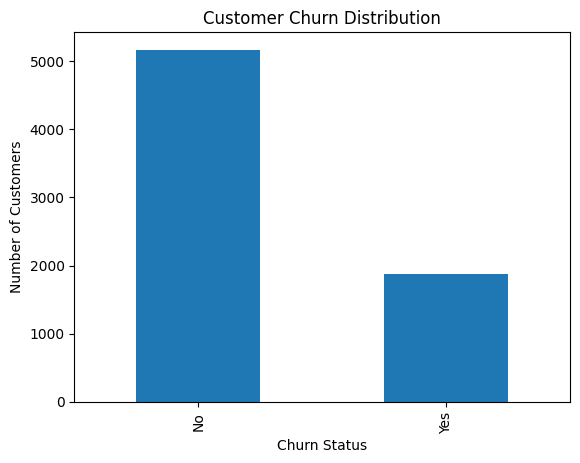

In [37]:
df["Churn"].value_counts().plot(kind = 'bar',title="Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


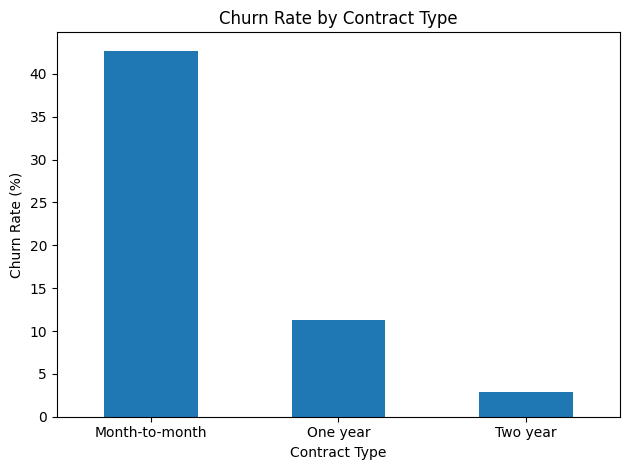

In [38]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)


contract_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar",
    title="Churn Rate by Contract Type",
    ylabel="Churn Rate (%)",
    xlabel="Contract Type"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


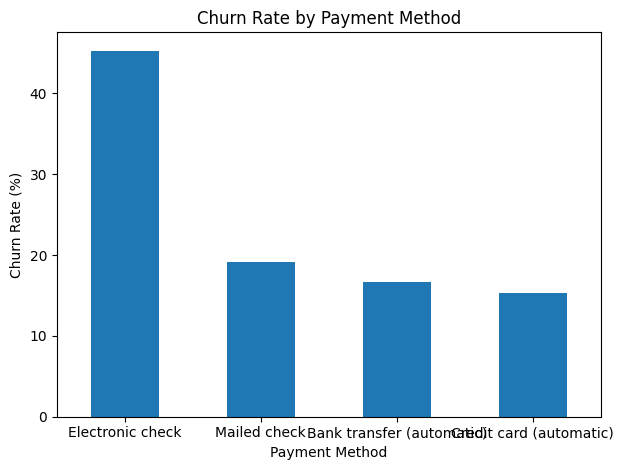

In [39]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn)


payment_churn["Yes"].sort_values(ascending=False).plot(
    kind="bar",
    title="Churn Rate by Payment Method",
    ylabel="Churn Rate (%)",
    xlabel="Payment Method"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Churn            No    Yes
TenureGroup               
0-12 months   52.56  47.44
13-24 months  71.29  28.71
25-48 months  79.61  20.39
49-72 months  90.49   9.51


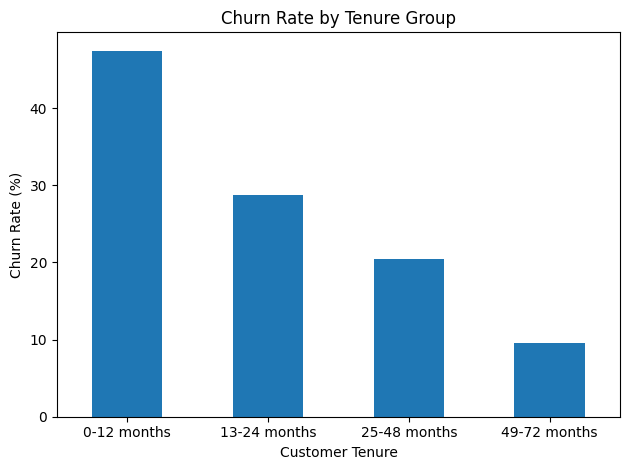

In [40]:
# Create tenure groups
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-72 months"]
)

# Calculate churn rate
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print(tenure_churn.round(2))

# Visualize churn rate
tenure_churn["Yes"].plot(
    kind="bar",
    title="Churn Rate by Tenure Group",
    ylabel="Churn Rate (%)",
    xlabel="Customer Tenure"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

        mean  median    min     max
Churn                              
No     61.27   64.43  18.25  118.75
Yes    74.44   79.65  18.85  118.35


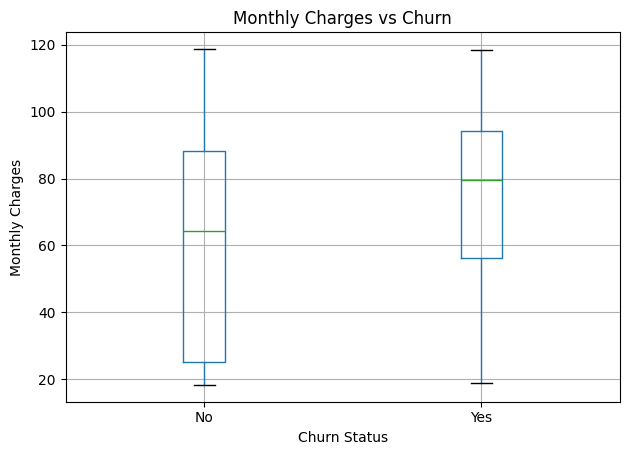

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

# Compare monthly charges for churned vs retained customers
print(df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "min", "max"]
).round(2))

# Visualize monthly charges
df.boxplot(
    column="MonthlyCharges",
    by="Churn"
)

plt.title("Monthly Charges vs Churn")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [42]:
# Compare total charges by churn status
print(
    df.groupby("Churn")["TotalCharges"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)

          mean   median    min      max
Churn                                  
No     2549.91  1679.52   0.00  8672.45
Yes    1531.80   703.55  18.85  8684.80


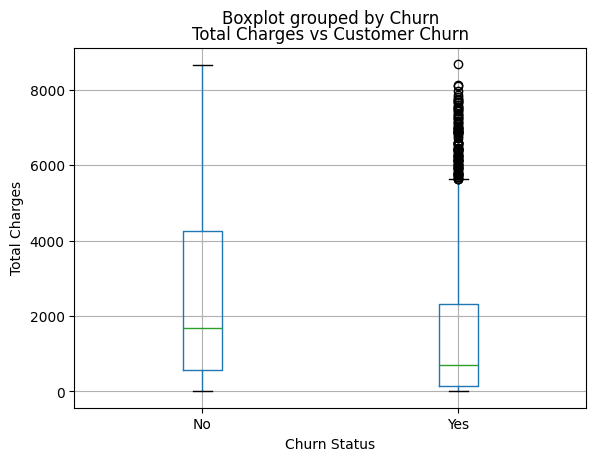

In [43]:
import matplotlib.pyplot as plt

df.boxplot(column="TotalCharges", by="Churn")

plt.title("Total Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Total Charges")
plt.show()

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


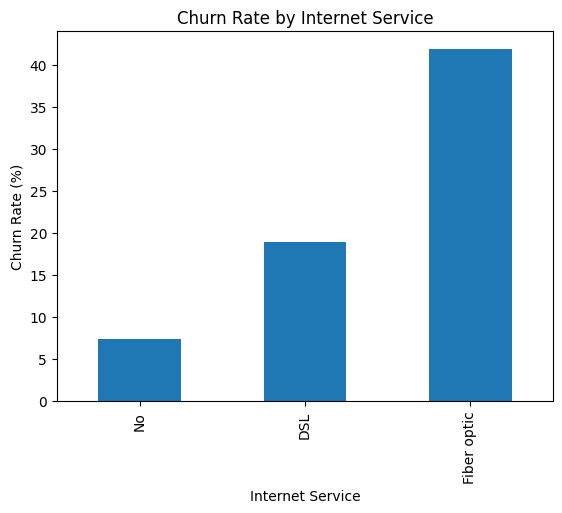

In [44]:
# Calculate churn rate by internet service
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.round(2))

# Visualize the results
internet_churn["Yes"].sort_values().plot(
    kind="bar",
    title="Churn Rate by Internet Service",
    ylabel="Churn Rate (%)",
    xlabel="Internet Service"
)

plt.show()

In [45]:
# Overall business KPIs
total_customers = len(df)
churned_customers = (df['Churn']=='Yes').sum()
retained_customers= (df['Churn']=='No').sum()
churn_rate = churned_customers/total_customers*100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print("Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54 %


In [47]:
# Churn rate by contract
print("Contract-wise churn rate:")
print(
    df.groupby("Contract", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

# Churn rate by internet service
print("\nInternet-service-wise churn rate:")
print(
    df.groupby("InternetService", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

Contract-wise churn rate:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Internet-service-wise churn rate:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


In [48]:
df.to_csv("Telco_Customer_Churn_Cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [49]:
print("Dataset Shape:", df.shape)

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Data Types:")
print(df.dtypes)

print("Churn Distribution:")
print(df["Churn"].value_counts())

Dataset Shape: (7043, 22)
Missing Values: 0
Duplicate Rows: 0
Data Types:
customerID            object
gender                object
SeniorCitizen          int64
Partner               object
Dependents            object
tenure                 int64
PhoneService          object
MultipleLines         object
InternetService       object
OnlineSecurity        object
OnlineBackup          object
DeviceProtection      object
TechSupport           object
StreamingTV           object
StreamingMovies       object
Contract              object
PaperlessBilling      object
PaymentMethod         object
MonthlyCharges       float64
TotalCharges         float64
Churn                 object
TenureGroup         category
dtype: object
Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [50]:
# Compare churn rate by contract and tenure group

risk_analysis = df.pivot_table(
    index="TenureGroup",
    columns="Contract",
    values="Churn",
    aggfunc=lambda x: (x == "Yes").mean() * 100,
    observed=False
).round(2)

print("Churn Rate by Tenure Group and Contract (%):")
display(risk_analysis)

Churn Rate by Tenure Group and Contract (%):


Contract,Month-to-month,One year,Two year
TenureGroup,,,
0-12 months,51.35,10.48,0.00
13-24 months,37.72,8.12,0.00
25-48 months,32.92,10.62,2.19
49-72 months,26.02,12.93,3.33



# Telco Customer Churn Analysis

## 1. Project Objective
Analyze customer churn patterns and identify factors associated with customer attrition.

## 2. Dataset Overview
- Total customers: 7,043
- Total columns after feature engineering: 22
- Target variable: Churn
- Tools: Python, Pandas, NumPy, Matplotlib, Seaborn

## 3. Data Cleaning
- Converted TotalCharges to numeric format.
- Handled 11 missing TotalCharges values for zero-tenure customers.
- Created TenureGroup for customer segmentation.
- Verified missing values and duplicate rows.

## 4. Key Findings
- Overall churn rate: 26.54%.
- Month-to-month contract churn: 42.71%.
- Two-year contract churn: 2.83%.
- Electronic check payment churn: 45.29%.
- Fiber optic customer churn: 41.89%.
- Churn for customers with 0–12 months tenure: 47.44%.

## 5. Business Recommendations
- Improve onboarding and early customer engagement.
- Investigate electronic payment customer experience.
- Test suitable long-term contract offers.
- Investigate customer concerns associated with fiber optic services.

## 6. Conclusion
The analysis identifies customer segments with higher churn rates
and provides actionable recommendations to support retention
strategies. The findings describe associations, not proven causes
of customer churn.
